In [ ]:

# Import libraries for loading and working with data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Import TF-IDF to convert text into numerical features
from sklearn.feature_extraction.text import TfidfVectorizer

# Import Support Vector Machine (SVM) classifier
from sklearn.svm import LinearSVC

# Import evaluation metrics to measure model performance
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


In [ ]:

# Connect Google Drive to access the dataset
from google.colab import drive
drive.mount('/content/drive')

# Update this path if your CSV files are stored in a different folder
data_path = "/content/drive/MyDrive/DS 340W/"

# Load the three datasets
train_df = pd.read_csv(data_path + "train.csv")
val_df = pd.read_csv(data_path + "validation.csv")
test_df = pd.read_csv(data_path + "test.csv")

# Check the number of rows in each dataset
print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

# Display the first five training examples
display(train_df.head())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training samples: 4494
Validation samples: 642
Testing samples: 1284


,id,tweet,label
0,477,The novel coronavirus can be cured by one bowl...,fake
1,2434,At the peak in New York on April 15 that state...,real
2,4689,Video shows a huge crowd gathered in an Americ...,fake
3,5106,(2/4) Containment zones that refer to a specif...,real
4,2635,Australian Scientists referred to coronavirus ...,fake


In [ ]:

# Extract tweet text and replace missing values with empty strings
X_train = train_df["tweet"].fillna("").astype(str)
X_val = val_df["tweet"].fillna("").astype(str)
X_test = test_df["tweet"].fillna("").astype(str)

# Extract the real/fake labels
y_train = train_df["label"].astype(str).str.strip().str.lower()
y_val = val_df["label"].astype(str).str.strip().str.lower()
y_test = test_df["label"].astype(str).str.strip().str.lower()

# Check which labels exist in the dataset
print("Training labels:")
print(y_train.value_counts())

# Make sure we only have the expected classes
assert set(y_train.unique()) == {"fake", "real"}
assert set(y_val.unique()) == {"fake", "real"}
assert set(y_test.unique()) == {"fake", "real"}


Training labels:
label
real    2352
fake    2142
Name: count, dtype: int64


In [ ]:

# Create a TF-IDF vectorizer
tfidf = TfidfVectorizer(
    max_features=10000,       # Keep up to 10,000 features
    ngram_range=(1, 2),       # Include individual words and two-word phrases
    min_df=2,                 # Ignore terms appearing in fewer than 2 documents
    max_df=0.95,              # Ignore terms appearing in over 95% of documents
    sublinear_tf=True         # Apply logarithmic scaling to term frequency
)

# Learn the vocabulary using ONLY the training data
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform validation and test data using the training vocabulary
# This prevents information from leaking into the training process
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

# Display the shape of the resulting feature matrices
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Validation TF-IDF shape:", X_val_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)


Training TF-IDF shape: (4494, 10000)
Validation TF-IDF shape: (642, 10000)
Testing TF-IDF shape: (1284, 10000)


In [ ]:

# Initialize a linear SVM classifier with default regularization
svm_baseline = LinearSVC(
    C=1.0,
    random_state=42,
    max_iter=10000
)

# Train the SVM model using the training dataset
svm_baseline.fit(X_train_tfidf, y_train)

# Predict labels for the validation dataset
val_predictions = svm_baseline.predict(X_val_tfidf)

# Calculate baseline validation metrics
baseline_accuracy = accuracy_score(y_val, val_predictions)
baseline_precision = precision_score(y_val, val_predictions, average="macro")
baseline_recall = recall_score(y_val, val_predictions, average="macro")
baseline_f1 = f1_score(y_val, val_predictions, average="macro")

# Print the baseline results
print("Baseline SVM Validation Results")
print(f"Accuracy:  {baseline_accuracy:.4f}")
print(f"Precision: {baseline_precision:.4f}")
print(f"Recall:    {baseline_recall:.4f}")
print(f"F1-score:  {baseline_f1:.4f}")


Baseline SVM Validation Results
Accuracy:  0.9424
Precision: 0.9423
Recall:    0.9422
F1-score:  0.9422


In [ ]:

# List of regularization strengths to test
c_values = [0.01, 0.1, 0.5, 1, 2, 5, 10]

# Store results for each model
tuning_results = []

# Track the best model and validation score
best_svm = None
best_c = None
best_f1 = -1

# Train and evaluate an SVM for each C value
for c in c_values:

    # Create the SVM model
    model = LinearSVC(
        C=c,
        random_state=42,
        max_iter=10000
    )

    # Train using only the training dataset
    model.fit(X_train_tfidf, y_train)

    # Predict validation labels
    predictions = model.predict(X_val_tfidf)

    # Calculate validation performance
    accuracy = accuracy_score(y_val, predictions)
    macro_f1 = f1_score(y_val, predictions, average="macro")

    # Save the results for comparison
    tuning_results.append({
        "C": c,
        "Accuracy": accuracy,
        "Macro F1": macro_f1
    })

    # Update the best model if its F1-score is higher
    if macro_f1 > best_f1:
        best_f1 = macro_f1
        best_c = c
        best_svm = model

# Display all tuning results
results_df = pd.DataFrame(tuning_results)
display(results_df)

print("Best C:", best_c)
print(f"Best validation macro F1: {best_f1:.4f}")


,C,Accuracy,Macro F1
0,0.01,0.895639,0.895076
1,0.10,0.926791,0.926573
2,0.50,0.942368,0.942215
3,1.00,0.942368,0.942233
4,2.00,0.942368,0.942250
5,5.00,0.933022,0.932885
6,10.00,0.933022,0.932885


Best C: 2
Best validation macro F1: 0.9422


In [ ]:

# Predict the test labels using the best SVM model
test_predictions = best_svm.predict(X_test_tfidf)

# Calculate final test metrics
test_accuracy = accuracy_score(y_test, test_predictions)
test_precision = precision_score(y_test, test_predictions, average="macro")
test_recall = recall_score(y_test, test_predictions, average="macro")
test_f1 = f1_score(y_test, test_predictions, average="macro")

# Print the final performance metrics
print("Final SVM Test Results")
print(f"Accuracy:  {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall:    {test_recall:.4f}")
print(f"F1-score:  {test_f1:.4f}")

# Show performance for fake and real news separately
print("\nClassification Report:")
print(classification_report(y_test, test_predictions, digits=4))


Final SVM Test Results
Accuracy:  0.9369
Precision: 0.9366
Recall:    0.9371
F1-score:  0.9368

Classification Report:
              precision    recall  f1-score   support

        fake     0.9275    0.9412    0.9343       612
        real     0.9457    0.9330    0.9393       672

    accuracy                         0.9369      1284
   macro avg     0.9366    0.9371    0.9368      1284
weighted avg     0.9370    0.9369    0.9369      1284



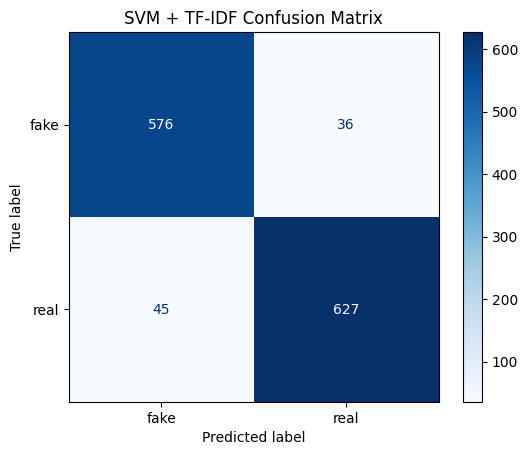

In [ ]:

# Define the class order for the confusion matrix
class_labels = ["fake", "real"]

# Calculate the confusion matrix
cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=class_labels
)

# Create the confusion matrix visualization
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_labels
)

disp.plot(cmap="Blues", values_format="d")

# Add a title to the visualization
plt.title("SVM + TF-IDF Confusion Matrix")
plt.show()


In [ ]:

# Import joblib to save trained scikit-learn objects
import joblib

# Save the best SVM model
joblib.dump(best_svm, data_path + "svm_tfidf_model.joblib")

# Save the fitted TF-IDF vectorizer
joblib.dump(tfidf, data_path + "svm_tfidf_vectorizer.joblib")

print("SVM model and TF-IDF vectorizer saved successfully!")


SVM model and TF-IDF vectorizer saved successfully!
